# Introduction to NetworkX

**NetworkX: Network Analysis in Python**

> NetworkX is a Python package for the creation, manipulation, and study of the structure, dynamics, and functions of complex networks.


Documentation for this package is available at https://networkx.github.io/.


First, let's import the library. It is commonly imported under the alias `nx`. 
And, you need to check the version of NetworkX. 

In [6]:
import networkx as nx
nx.__version__

'3.1'

If the NetworkX package is not installed, then you can install it here, or anaconda prompt like: 

In [8]:
#!pip install networkx

This is how we can create an empty graph with no nodes and no edges.

In [10]:
G = nx.Graph()

### Nodes

We can add one node at a time,

In [13]:
G.add_node(1)

with attributes

We don't need to see every graph for each cell, but if you want to see the graph, this will do. 
```python
nx.draw(G)
```

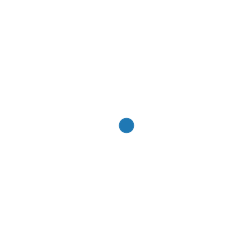

In [16]:
# basic graph drawing capability
%matplotlib inline
import matplotlib.pyplot as plt

# You can control the size of figure using figsize: (row, column).
plt.figure(figsize=(4,4), dpi=60) 
nx.draw(G)

If you want to see the index of each node, simply add this `with_labels`.

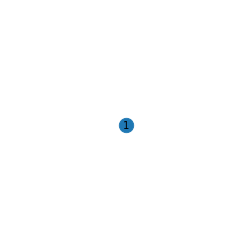

In [18]:
plt.figure(figsize=(4,4), dpi=60)
nx.draw(G, with_labels=True)

In [19]:
G.add_node(2, country="DE")

or add nodes from a list

In [21]:
G.add_nodes_from([3, 4])

We can also add nodes along with node attributes if your container yields 2-tuples of the form `(node, node_attribute_dict)`:

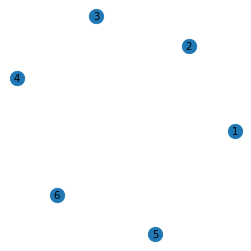

In [23]:
G.add_nodes_from(
    [
        (5, {"color": "red"}),
        (6, {"color": "green"}),
    ]
)

plt.figure(figsize=(4,4), dpi=60) 
nx.draw(G, with_labels=True)

### Edges

`G` can also be grown by adding one edge at a time,

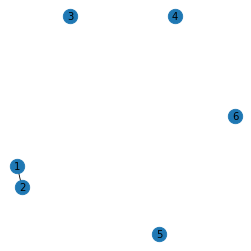

In [26]:
G.add_edge(1, 2)

plt.figure(figsize=(4,4), dpi=60) 
nx.draw(G, with_labels=True)

even with attributes

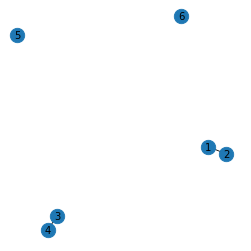

In [28]:
G.add_edge(3, 4, weight=2)
plt.figure(figsize=(4,4), dpi=60) 
nx.draw(G, with_labels=True)

or by adding a list of edges,

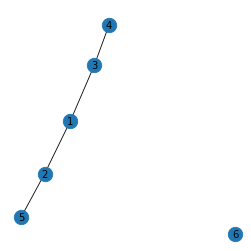

In [30]:
G.add_edges_from([(1, 3), (2, 5)])

plt.figure(figsize=(4,4), dpi=60) 
nx.draw(G, with_labels=True)

or as a 3-tuple with 2 nodes followed by an edge attribute dictionary

In [32]:
G.add_edges_from([(2, 3, {"weight": 3})])

### Examining elements of a graph

We can examine the nodes and edges.

In [35]:
G.nodes

NodeView((1, 2, 3, 4, 5, 6))

In [36]:
G.number_of_nodes()

6

In [37]:
G.edges

EdgeView([(1, 2), (1, 3), (2, 5), (2, 3), (3, 4)])

In [38]:
G.number_of_edges()

5

### Accessing graph elements

Access an edge:

In [41]:
G.edges[2, 3]

{'weight': 3}

Access an attribute of an edge:

In [43]:
G.edges[2, 3]["weight"]

3

Find all neighbours of node 1:

In [45]:
G[1]

AtlasView({2: {}, 3: {}})

### Removing elements

One can remove nodes and edges from the graph in a similar fashion to adding. Use methods `G.remove_node()`, `G.remove_nodes_from()`, `G.remove_edge()` and `G.remove_edges_from()`, e.g.

In [48]:
G.remove_node(5)

In [49]:
# G.remove_edge(2, 5) # this will result in an error.

**NOTE**: Removing a node will also remove all adjacent edges!

You can remove all nodes and edges with

In [52]:
# G.clear()


There are some options for a figure, so we can use them to change the figure. 

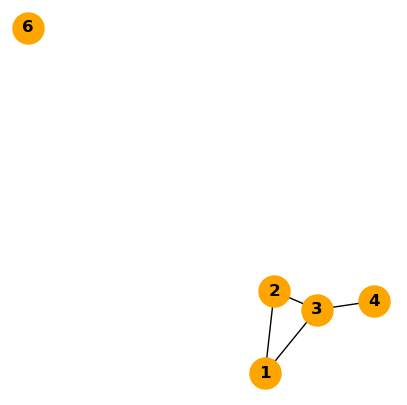

In [54]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
nx.draw(G, with_labels=True, ax=ax, node_color="orange", node_size = 500, font_weight="bold")
plt.savefig("tmp.png")

For a full list of arguments of the function see
https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx.html

### Analysing graphs

The `networkx` library comes with many functions to analyse graphs. Here are a few examples we're going to need for linearised power flow calculations in electricity transmission networks:

Are all nodes in the network connected with each other?

In [ ]:
nx.is_connected(G)

What are the components that are connected / isolated?

In [ ]:
list(nx.connected_components(G))

Is the network planar? I.e. can the graph be drawn such that edges don't cross?

In [ ]:
nx.is_planar(G)

What is the frequency of degrees in the network?

In [ ]:
nx.degree_histogram(G)

In [ ]:
import pandas as pd

pd.Series(nx.degree_histogram(G))

What is the *adjacency matrix*? (Careful, `networkx` will yield a weighted adjacency matrix by default!)

In [ ]:
A = nx.adjacency_matrix(G, weight=None).todense()
A

What is the *incidence matrix*? (Careful, `networkx` will yield a incidence matrix without orientation by default!)

In [ ]:
nx.incidence_matrix(G, oriented=True).todense()

# Directed graphs

Unless otherwise specified, we assume graph edges are undirected -- they are symmetric and go both ways. But some relationships, e.g. predator-prey relationships, are asymmetric and best represented as directed graphs. NetworkX provides the `DiGraph` class for directed graphs.

In [ ]:
D = nx.DiGraph()

D.add_edges_from([(1,2),(2,3),(3,2),(3,4),(3,5),(4,5),(4,6),(5,6),(6,4),(4,2)])

plt.figure(figsize=(5,4), dpi=60) 
nx.draw(D, with_labels=True, node_color="red")

Note the asymmetry in graph methods dealing with edges such as `has_edge()`:

In [ ]:
D.has_edge(1,2)

In [ ]:
D.has_edge(2,1)

Instead of the symmetric relationship "neighbors", nodes in directed graphs have predecessors ("in-neighbors") and successors ("out-neighbors"):

In [ ]:
print('Successors of 2:', list(D.successors(2)))

print('Predecessors of 2:', list(D.predecessors(2)))

In [ ]:
D.in_degree(2)

In [ ]:
D.out_degree(2)

### Caveat

Since NetworkX 2, the `.degree()` method on a directed graph gives the total degree: in-degree plus out-degree. However, in a bit of confusing nomenclature, the `neighbors` method is a synonym for `successors`, giving only the edges originating from the given node. This makes sense if you consider `neighbors` to be all the nodes reachable from the given node by following links, but it's easy to make the mistake of writing `.neighbors()` in your code when you really want both predecessors and successors.

In [ ]:
D.degree(2)

In [ ]:
print('Successors of 2:', list(D.successors(2)))
print('"Neighbors" of 2:', list(D.neighbors(2)))

`add_weighted_edges_from()`: when you want to assign weights on edges. 

In [ ]:
# directed graph
DG = nx.DiGraph()
DG.add_weighted_edges_from([(1, 2 ,0.5), (3, 1, 1.0)])
DG.out_degree(1, weight='weight')
plt.figure(figsize=(5,4), dpi=60) 
nx.draw(DG, with_labels=True)